## 1. Import Libraries and Load Dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Load dataset
df = pd.read_csv('Churn_Modelling.csv')
display(df.head())
print("Dataset Shape:", df.shape)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Dataset Shape: (10000, 14)


## 2. Preprocessing, Feature Selection, and Split

In [16]:
# Drop irrelevant columns
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True, errors='ignore')

# One-hot encode categorical features
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

# Distinguish features and target
X = df.drop('Exited', axis=1)
y = df['Exited']

# Split dataset into train and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Data Normalization

In [17]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## 4. Build and Train Models
We'll build a baseline network and then an improved model with wider architecture and Dropout regularizations to enhance generalization.

In [18]:
# Baseline Model
baseline_model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_baseline = baseline_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7759 - loss: 0.5128 - val_accuracy: 0.7987 - val_loss: 0.4573
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7950 - loss: 0.4527 - val_accuracy: 0.8075 - val_loss: 0.4342
Epoch 3/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8042 - loss: 0.4381 - val_accuracy: 0.8150 - val_loss: 0.4248
Epoch 4/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8086 - loss: 0.4299 - val_accuracy: 0.8200 - val_loss: 0.4189
Epoch 5/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8152 - loss: 0.4225 - val_accuracy: 0.8263 - val_loss: 0.4119
Epoch 6/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8213 - loss: 0.4135 - val_accuracy: 0.8313 - val_loss: 0.4029
Epoch 7/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8300 - loss: 0.3966 - val_accuracy: 0.8413 - val_loss: 0.3854
Epoch 8/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8389 - loss: 0.3768 - val_accuracy: 0.8494 - val_

In [19]:
# Improved Model (using dropout layers to prevent overfitting, wider layers, and slightly more epochs)
improved_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.1),
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(1, activation='sigmoid')
])

improved_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_improved = improved_model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7964 - loss: 0.4753 - val_accuracy: 0.8075 - val_loss: 0.4271
Epoch 2/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8059 - loss: 0.4316 - val_accuracy: 0.8363 - val_loss: 0.4077
Epoch 3/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8267 - loss: 0.4126 - val_accuracy: 0.8450 - val_loss: 0.3907
Epoch 4/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8394 - loss: 0.3967 - val_accuracy: 0.8469 - val_loss: 0.3744
Epoch 5/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8422 - loss: 0.3849 - val_accuracy: 0.8525 - val_loss: 0.3642
Epoch 6/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8472 - loss: 0.3694 - val_accuracy: 0.8581 - val_loss: 0.3582
Epoch 7/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8470 - loss: 0.3662 - val_accuracy: 0.8569 - val_loss: 0.3543
Epoch 8/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8520 - loss: 0.3594 - val_accuracy: 0.

## 5. Model Evaluation

In [20]:
# Predict and evaluate
y_pred_base = (baseline_model.predict(X_test) > 0.5).astype(int)
y_pred_imp = (improved_model.predict(X_test) > 0.5).astype(int)

print("=== Baseline Model Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_base):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_base))

print("\n=== Improved Model Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_imp):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_imp))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
=== Baseline Model Evaluation ===
Accuracy Score: 0.8575
Confusion Matrix:
[[1541   66]
 [ 219  174]]

=== Improved Model Evaluation ===
Accuracy Score: 0.8620
Confusion Matrix:
[[1545   62]
 [ 214  179]]


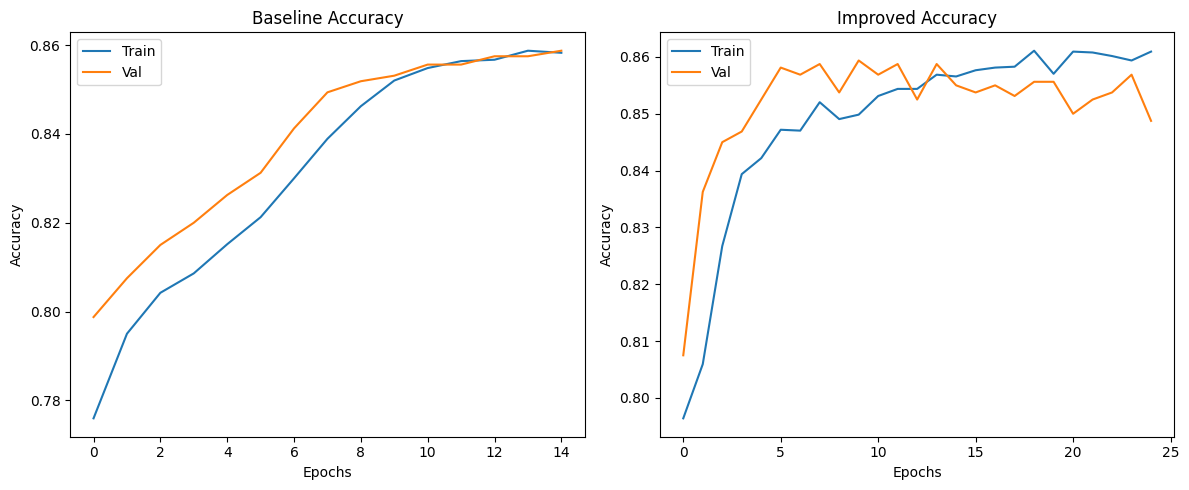

In [21]:
# Compare performance curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['accuracy'], label='Train')
plt.plot(history_baseline.history['val_accuracy'], label='Val')
plt.title('Baseline Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_improved.history['accuracy'], label='Train')
plt.plot(history_improved.history['val_accuracy'], label='Val')
plt.title('Improved Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()